# PathSnap – Person B: Dataset Exploration

**Notebook 01** | Descriptive inspection of permitted development data.

Rules: inspect `train` and `student_test` only. Do not inspect evaluator-testing data during development. Do not assume GPS rows align positionally with route rows. Raw files are whitespace-separated and headerless.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 100)
try:
    import networkx as nx
    NETWORKX_AVAILABLE = True
except ImportError:
    NETWORKX_AVAILABLE = False
    print("Install networkx for connectivity analysis: pip install networkx")

# Update this path for your repository layout.
DATA_ROOT = Path("data/raw/Student folder")  # Paths are resolved from the repository root
TRAIN_DIR = DATA_ROOT / "train"
STUDENT_TEST_DIR = DATA_ROOT / "student_test"
EXTENSIONS = [".track", ".nodes", ".arcs", ".route"]

## 2. Discover trips and inspect file availability

In [2]:
def discover_trips(folder):
    if not folder.exists():
        raise FileNotFoundError(f"Not found: {folder.resolve()}. Update DATA_ROOT.")
    return sorted(p.name for p in folder.iterdir() if p.is_dir())

def file_path(folder, trip_id, ext):
    return folder / trip_id / f"{trip_id}{ext}"

train_ids = discover_trips(TRAIN_DIR)
student_ids = discover_trips(STUDENT_TEST_DIR)
print("Training trips:", len(train_ids))
print("Student-testing trips:", len(student_ids))

def inventory_for(folder, ids, partition):
    rows=[]
    for tid in ids:
        r={"partition":partition,"trip_id":tid}
        for ext in EXTENSIONS:
            p=file_path(folder,tid,ext)
            r[ext[1:]+"_exists"]=p.is_file()
            r[ext[1:]+"_bytes"]=p.stat().st_size if p.is_file() else np.nan
        rows.append(r)
    return pd.DataFrame(rows)
inventory=pd.concat([inventory_for(TRAIN_DIR,train_ids,"train"),inventory_for(STUDENT_TEST_DIR,student_ids,"student_test")],ignore_index=True)
display(inventory.head(10))
display(inventory.groupby("partition")[[e[1:]+"_exists" for e in EXTENSIONS]].sum())

Training trips: 80
Student-testing trips: 10


,partition,trip_id,track_exists,track_bytes,nodes_exists,nodes_bytes,arcs_exists,arcs_bytes,route_exists,route_bytes
0,train,00000001,True,40975,True,1687371,True,1948474,True,3119
1,train,00000002,True,238085,True,158720,True,156519,True,1398
2,train,00000003,True,26164,True,182760,True,175733,True,411
3,train,00000004,True,34982,True,147000,True,149738,True,1582
4,train,00000005,True,33378,True,17960,True,12351,True,421
5,train,00000006,True,47576,True,65180,True,62914,True,1184
6,train,00000008,True,104055,True,104895,True,99150,True,832
7,train,00000010,True,88356,True,170040,True,153188,True,1042
8,train,00000011,True,92217,True,52980,True,49400,True,2167
9,train,00000012,True,51960,True,327520,True,410744,True,859


,track_exists,nodes_exists,arcs_exists,route_exists
partition,,,,
student_test,10,10,10,10
train,80,80,80,80


## 3. Read raw files using the documented schemas

In [3]:
def read_trip(folder, tid):
    p={e:file_path(folder,tid,e) for e in EXTENSIONS}
    missing=[str(v) for v in p.values() if not v.is_file()]
    if missing: raise FileNotFoundError(f"{tid}: missing {missing}")
    return {
        "track":pd.read_csv(p[".track"],sep=r"\s+",header=None,names=["longitude","latitude","timestamp"]),
        "nodes":pd.read_csv(p[".nodes"],sep=r"\s+",header=None,names=["longitude","latitude"]),
        "arcs":pd.read_csv(p[".arcs"],sep=r"\s+",header=None,names=["from_node_id","to_node_id"]),
        "route":pd.read_csv(p[".route"],sep=r"\s+",header=None,names=["arc_id"])}

sample_id=train_ids[0]
sample=read_trip(TRAIN_DIR,sample_id)
for name,df in sample.items():
    print(name, df.shape)
    display(df.head())

track (1315, 3)


,longitude,latitude,timestamp
0,8.595203,49.844053,1.0
1,8.595294,49.844441,2.0
2,8.595352,49.844883,3.0
3,8.595390,49.845379,4.0
4,8.595587,49.845750,5.0


nodes (88809, 2)


,longitude,latitude
0,8.581679,49.857880
1,8.584637,49.858295
2,8.580173,49.858567
3,8.584392,49.859119
4,8.584935,49.857396


arcs (165790, 2)


,from_node_id,to_node_id
0,0,281
1,0,1
2,0,5
3,1,0
4,1,40750


route (525, 1)


,arc_id
0,2641
1,64973
2,133948
3,133949
4,139208


## 4. Per-trip quality and size summary

In [4]:
def haversine_km(lon1,lat1,lon2,lat2):
    R=6371.0088
    lon1,lat1,lon2,lat2=map(np.radians,[lon1,lat1,lon2,lat2])
    a=np.sin((lat2-lat1)/2)**2+np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 2*R*np.arcsin(np.sqrt(a))

def summarise(folder,tid,partition):
    d=read_trip(folder,tid); t,n,a,r=d["track"],d["nodes"],d["arcs"],d["route"]
    dt=t.timestamp.diff().dropna(); valid=t.longitude.between(-180,180)&t.latitude.between(-90,90)&t.notna().all(axis=1)
    node_ids=set(range(len(n)))
    bad_endpoints=sum(int(u) not in node_ids or int(v) not in node_ids for u,v in a.itertuples(index=False,name=None))
    bad_route=int((~r.arc_id.between(0,len(a)-1)).sum()) if len(a) else len(r)
    step=haversine_km(t.longitude.shift(),t.latitude.shift(),t.longitude,t.latitude)
    return {"partition":partition,"trip_id":tid,"gps_observations":len(t),"nodes":len(n),"arcs":len(a),"route_arcs":len(r),
      "missing_gps_rows":int(t.isna().any(axis=1).sum()),"invalid_gps_rows":int((~valid).sum()),
      "duplicate_timestamps":int(t.timestamp.duplicated().sum()),"non_increasing_steps":int((dt<=0).sum()),
      "non_1s_steps":int((dt!=1).sum()),"max_time_gap_s":float(dt.max()) if len(dt) else np.nan,
      "invalid_arc_endpoints":bad_endpoints,"invalid_route_arc_ids":bad_route,
      "longitude_min":t.longitude.min(),"longitude_max":t.longitude.max(),"latitude_min":t.latitude.min(),"latitude_max":t.latitude.max(),
      "gps_path_length_km":float(step.sum()),
      **{e[1:]+"_bytes":file_path(folder,tid,e).stat().st_size for e in EXTENSIONS}}

rows=[summarise(TRAIN_DIR,x,"train") for x in train_ids]+[summarise(STUDENT_TEST_DIR,x,"student_test") for x in student_ids]
trip_summary=pd.DataFrame(rows)
display(trip_summary.head())
display(trip_summary.groupby("partition").describe().T)

,partition,trip_id,gps_observations,nodes,arcs,route_arcs,missing_gps_rows,invalid_gps_rows,duplicate_timestamps,non_increasing_steps,non_1s_steps,max_time_gap_s,invalid_arc_endpoints,invalid_route_arc_ids,longitude_min,longitude_max,latitude_min,latitude_max,gps_path_length_km,track_bytes,nodes_bytes,arcs_bytes,route_bytes
0,train,00000001,1315,88809,165790,525,0,0,0,0,25,16.0,0,0,8.570524,8.647860,49.844053,50.211882,50.186254,40975,1687371,1948474,3119
1,train,00000002,7243,7936,16139,262,0,0,0,0,185,160.0,0,0,10.999961,11.050902,47.658344,47.695459,55.872411,238085,158720,156519,1398
2,train,00000003,821,9138,18028,79,0,0,0,0,3,2.0,0,0,37.154202,37.201595,55.977135,56.007585,8.420171,26164,182760,175733,411
3,train,00000004,1064,7350,15499,320,0,0,0,0,491,51.0,0,0,12.342280,12.459615,52.590308,52.718960,27.891064,34982,147000,149738,1582
4,train,00000005,1045,898,1579,105,0,0,0,0,0,1.0,0,0,35.485577,35.544315,49.357581,49.613085,31.325987,33378,17960,12351,421


partition               student_test         train
gps_observations count     10.000000     80.000000
                 mean    1916.000000   2605.212500
                 std     1335.432348   3312.345399
                 min      262.000000    361.000000
                 25%      917.750000    945.750000
...                              ...           ...
route_bytes      min      474.000000    253.000000
                 25%      746.000000    816.500000
                 50%     1176.500000   1397.000000
                 75%     1950.000000   2647.000000
                 max     7628.000000  12121.000000

[168 rows x 2 columns]

## 5. Timestamp and trajectory plots

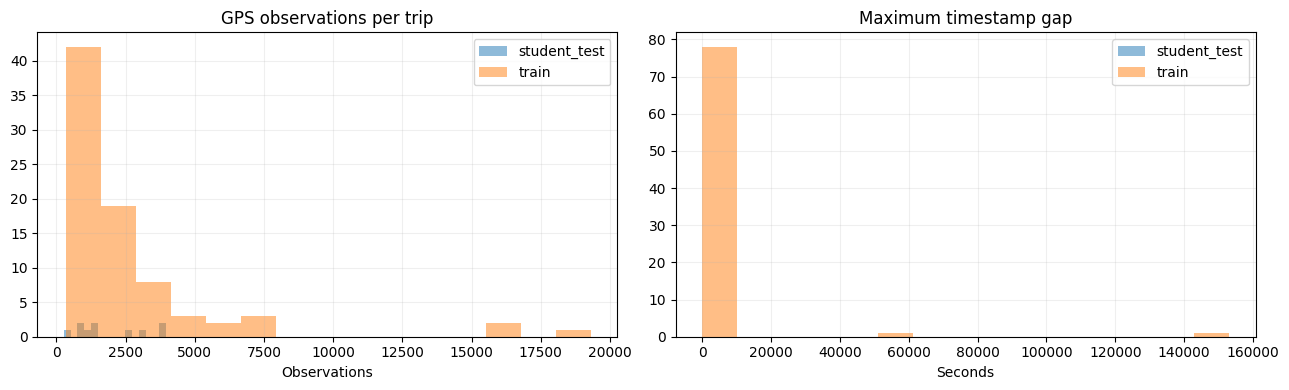

,partition,trip_id,missing_gps_rows,invalid_gps_rows,duplicate_timestamps,non_increasing_steps,non_1s_steps,max_time_gap_s
72,train,00000090,0,0,0,0,224,153064.0
61,train,00000078,0,0,0,0,712,52810.0
55,train,00000069,0,0,0,0,22,2658.0
16,train,00000021,0,0,0,0,6,2161.0
8,train,00000011,0,0,0,0,1,909.0
34,train,00000042,0,0,0,0,81,670.0
64,train,00000081,0,0,0,0,903,536.0
18,train,00000024,0,0,0,0,23,458.0
36,train,00000044,0,0,0,0,54,341.0
67,train,00000084,0,0,0,0,50,312.0


In [5]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
for name,g in trip_summary.groupby("partition"):
    ax[0].hist(g.gps_observations,bins=15,alpha=.5,label=name)
    ax[1].hist(g.max_time_gap_s.dropna(),bins=15,alpha=.5,label=name)
ax[0].set(title="GPS observations per trip",xlabel="Observations")
ax[1].set(title="Maximum timestamp gap",xlabel="Seconds")
for a in ax: a.legend(); a.grid(alpha=.2)
plt.tight_layout(); plt.show()
display(trip_summary[["partition","trip_id","missing_gps_rows","invalid_gps_rows","duplicate_timestamps","non_increasing_steps","non_1s_steps","max_time_gap_s"]].sort_values("max_time_gap_s",ascending=False).head(20))

## 6. Road-network connectivity

In [6]:
def connectivity(arcs,n_nodes):
    if not NETWORKX_AVAILABLE: return {"status":"networkx unavailable"}
    G=nx.Graph(); G.add_nodes_from(range(n_nodes)); G.add_edges_from(arcs.itertuples(index=False,name=None))
    comps=list(nx.connected_components(G)); largest=max((len(c) for c in comps),default=0)
    return {"components":len(comps),"isolated_nodes":sum(deg==0 for _,deg in G.degree()),
            "largest_component_nodes":largest,"largest_component_fraction":largest/n_nodes if n_nodes else np.nan}

conn=[]
for partition,folder,ids in [("train",TRAIN_DIR,train_ids),("student_test",STUDENT_TEST_DIR,student_ids)]:
    for tid in ids:
        d=read_trip(folder,tid); conn.append({"partition":partition,"trip_id":tid,**connectivity(d["arcs"],len(d["nodes"]))})
connectivity_df=pd.DataFrame(conn)
display(connectivity_df)

,partition,trip_id,components,isolated_nodes,largest_component_nodes,largest_component_fraction
0,train,00000001,175,0,86854,0.977986
1,train,00000002,14,0,7750,0.976562
2,train,00000003,42,0,8625,0.943861
3,train,00000004,12,0,7254,0.986939
4,train,00000005,3,0,888,0.988864
...,...,...,...,...,...,...
85,student_test,00000056,24,0,14427,0.977505
86,student_test,00000065,5,0,6388,0.990695
87,student_test,00000076,40,0,25629,0.962230
88,student_test,00000077,11,0,4297,0.971293


## 7. Plot one trip against its road-network nodes

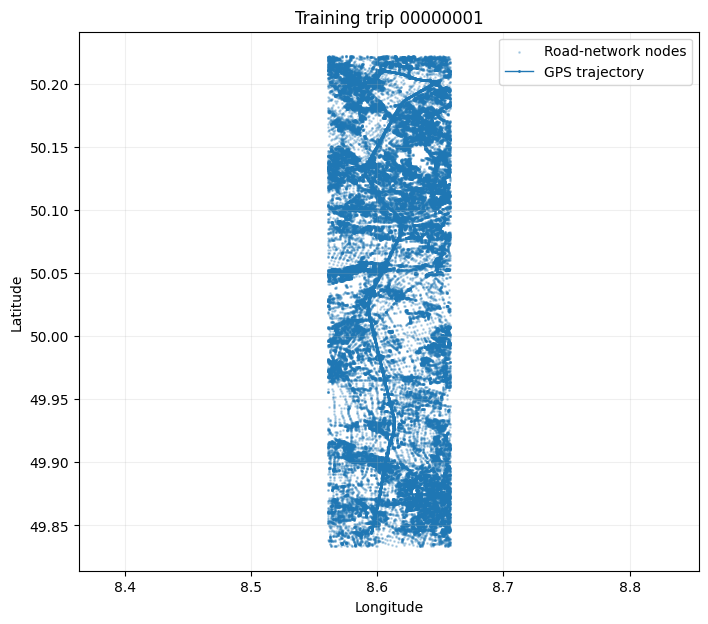

In [7]:
d=read_trip(TRAIN_DIR,sample_id); tr,nd=d["track"],d["nodes"]
plt.figure(figsize=(8,7))
plt.scatter(nd.longitude,nd.latitude,s=1,alpha=.25,label="Road-network nodes")
plt.plot(tr.longitude,tr.latitude,linewidth=1,marker=".",markersize=2,label="GPS trajectory")
plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.title(f"Training trip {sample_id}")
plt.axis("equal"); plt.grid(alpha=.2); plt.legend(); plt.show()

## 8. Export descriptive outputs

In [8]:
OUTPUT_DIR=Path("outputs/exploration")  # repository-root relative
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
inventory.to_csv(OUTPUT_DIR/"file_inventory.csv",index=False)
trip_summary.to_csv(OUTPUT_DIR/"trip_summary.csv",index=False)
connectivity_df.to_csv(OUTPUT_DIR/"connectivity_summary.csv",index=False)
print("Saved outputs to",OUTPUT_DIR.resolve())

Saved outputs to /mnt/data/pathsnap_work/repo/outputs/exploration


## 9. Findings and handoff checklist

Complete these notes after running the notebook; do not invent findings.

- [ ] Confirmed training and student-testing trip counts.
- [ ] Checked raw file availability.
- [ ] Reviewed GPS validity and timestamp gaps.
- [ ] Checked node/arc counts and endpoint references.
- [ ] Checked route arc IDs against arc indices.
- [ ] Reviewed disconnected components and isolated nodes.
- [ ] Shared anomalies with Person A.
- [ ] Confirmed candidate-table schema with Person A.

**Before model training, Person A must confirm candidate generation, observation-to-route alignment, label definition, feature columns and `trip_id`. Never assume GPS row index equals route row index.**